## Inference Lab: Optimal Price
#### Name: Anna Phillips

In [223]:
# code for set up

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

rng = np.random.default_rng(100)

def purchase_probability(price):
    price = np.asarray(price, dtype=float)
    return (
        0.55 * np.exp(-np.logaddexp(0.0, (price - 13.9) / 0.8))
        + 0.30 * np.exp(-np.logaddexp(0.0, (price - 30.9) / 1.2))
        + 0.15 * np.exp(-np.logaddexp(0.0, (price - 58.4) / 1.8))
    )

def sales(price=14.0, rng=None, mean_customers=30):
    price = float(price)
    if not np.isfinite(price):
        raise ValueError("price must be finite")
    if price < 0:
        raise ValueError("price must be nonnegative")
    mean_customers = float(mean_customers)
    if not np.isfinite(mean_customers) or mean_customers < 0:
        raise ValueError("mean_customers must be finite and nonnegative")
    rng = np.random.default_rng(rng)
    customer_count = rng.poisson(mean_customers)
    probability = purchase_probability(price)
    return rng.binomial(1, probability, size=customer_count).astype(np.int8)

In [224]:
# simple grid search to get started

# set 90% confidence interval
critical_value = 1.645

# list of prices to test
prices = np.arange(0, 71, 5)

# set mean customer size
customer_sizes = [100, 200, 500, 1000, 2000, 5000]

# create function for easier rerunning
def local_search(customer_sizes, prices):

    grid_results = []

    for mean_customers in customer_sizes:

        for price in prices:

            revenue = sales(
                price,
                mean_customers = mean_customers,
                rng = rng
            ) * price

            mean_revenue = revenue.mean()
            # calculate number of customers
            customers = len(revenue)

            se = revenue.std(ddof=1) / np.sqrt(customers)

            ci_low = mean_revenue - critical_value * se
            ci_high = mean_revenue + critical_value * se

            grid_results.append({
                "mean_customers": mean_customers,
                "price": price,
                "mean_revenue": mean_revenue,
                "se": se,
                "ci_low": ci_low,
                "ci_high": ci_high,
                "customers": customers
            })

    return pd.DataFrame(grid_results)

# create data frame of experimentation results
grid_df = local_search(customer_sizes, prices)

In [225]:
# test data frame
grid_df.sort_values(
    ["mean_customers", "price"]
)

,mean_customers,price,mean_revenue,se,ci_low,ci_high,customers
0,100,0,0.000000,0.000000,0.000000,0.000000,111
1,100,5,5.000000,0.000000,5.000000,5.000000,108
2,100,10,10.000000,0.000000,10.000000,10.000000,101
3,100,15,7.568807,0.721657,6.381681,8.755934,109
4,100,20,9.387755,1.013441,7.720644,11.054866,98
...,...,...,...,...,...,...,...
85,5000,50,7.452924,0.250733,7.040469,7.865379,5045
86,5000,55,7.020817,0.257228,6.597676,7.443957,5092
87,5000,60,2.399518,0.166678,2.125332,2.673703,4976
88,5000,65,0.308300,0.062788,0.205014,0.411587,5060


In [226]:
# top three prices by mean_revenue for each customer size
grid_df.sort_values(["mean_customers", "mean_revenue"], ascending=[True, False]).groupby("mean_customers").head(3)

,mean_customers,price,mean_revenue,se,ci_low,ci_high,customers
10,100,50,12.105263,2.209086,8.471317,15.739210,95
5,100,25,10.396040,1.232166,8.369126,12.422953,101
2,100,10,10.000000,0.000000,10.000000,10.000000,101
21,200,30,11.465969,1.057581,9.726248,13.205689,191
20,200,25,11.312849,0.932680,9.778591,12.847107,179
17,200,10,9.943503,0.056497,9.850565,10.036441,177
35,500,25,12.074148,0.559813,11.153256,12.995041,499
32,500,10,9.978118,0.021882,9.942123,10.014114,457
36,500,30,9.550781,0.618226,8.533799,10.567763,512
50,1000,25,11.654527,0.402512,10.992395,12.316659,961


In [227]:
# mean revenue by customer size for 20, 25, 30
grid_df[
    grid_df["price"].between(20, 35)
].sort_values(
    ["mean_customers", "price"]
)

,mean_customers,price,mean_revenue,se,ci_low,ci_high,customers
4,100,20,9.387755,1.013441,7.720644,11.054866,98
5,100,25,10.396040,1.232166,8.369126,12.422953,101
6,100,30,10.000000,1.348400,7.781882,12.218118,111
7,100,35,5.894737,1.350996,3.672348,8.117125,95
19,200,20,7.845304,0.727848,6.647994,9.042614,181
20,200,25,11.312849,0.932680,9.778591,12.847107,179
21,200,30,11.465969,1.057581,9.726248,13.205689,191
22,200,35,6.381215,1.007259,4.724275,8.038156,181
34,500,20,8.471954,0.435056,7.756287,9.187620,517
35,500,25,12.074148,0.559813,11.153256,12.995041,499


In [228]:
# re-run brute force grid search with smaller range
prices = np.arange(20, 31, 1)

refined_grid_df = local_search(customer_sizes, prices)

In [229]:
# test data frame
refined_grid_df

,mean_customers,price,mean_revenue,se,ci_low,ci_high,customers
0,100,20,6.595745,0.975016,4.991843,8.199646,94
1,100,21,9.757576,1.058005,8.017157,11.497995,99
2,100,22,8.962963,1.045017,7.243910,10.682016,108
3,100,23,9.419048,1.109052,7.594657,11.243438,105
4,100,24,11.400000,1.098662,9.592701,13.207299,120
...,...,...,...,...,...,...,...
61,5000,26,11.503783,0.182244,11.203992,11.803574,5022
62,5000,27,12.052505,0.190390,11.739313,12.365696,4971
63,5000,28,12.092913,0.194613,11.772775,12.413052,5080
64,5000,29,11.663555,0.202584,11.330305,11.996805,4928


In [230]:
# top three prices by mean_revenue for each customer size
refined_grid_df.sort_values(["mean_customers", "mean_revenue"], ascending=[True, False]).groupby("mean_customers").head(3)

,mean_customers,price,mean_revenue,se,ci_low,ci_high,customers
6,100,26,14.061224,1.315545,11.897154,16.225295,98
7,100,27,12.085714,1.316500,9.920072,14.251356,105
10,100,30,12.000000,1.515873,9.506388,14.493612,95
17,200,26,12.853933,0.977078,11.246639,14.461226,178
16,200,25,11.309524,0.860713,9.893651,12.725396,210
18,200,27,11.305419,0.937222,9.763688,12.847149,203
31,500,29,12.772340,0.664778,11.678780,13.865901,470
29,500,27,12.718147,0.592733,11.743101,13.693192,518
30,500,28,12.476386,0.631281,11.437929,13.514843,487
40,1000,27,12.620690,0.417127,11.934516,13.306864,1044


In [231]:
# create power analysis function

def run_power_analysis(
    price_pairs,
    customer_sizes,
    critical_value,
    n_experiments=100,
    rng=None
):
    power_results = []

    for pair_name, (price_A, price_B) in price_pairs.items():

        for mean_customers in customer_sizes:

            significant_results = 0

            for i in range(n_experiments):

                revenue_A = (
                    sales(
                        price_A,
                        mean_customers=mean_customers,
                        rng=rng
                    ) * price_A
                )

                revenue_B = (
                    sales(
                        price_B,
                        mean_customers=mean_customers,
                        rng=rng
                    ) * price_B
                )

                mean_diff = revenue_B.mean() - revenue_A.mean()

                se_diff = np.sqrt(
                    revenue_A.var(ddof=1) / len(revenue_A)
                    +
                    revenue_B.var(ddof=1) / len(revenue_B)
                )

                ci_low = mean_diff - critical_value * se_diff
                ci_high = mean_diff + critical_value * se_diff

                if ci_low > 0 or ci_high < 0:
                    significant_results += 1

            power = significant_results / n_experiments

            power_results.append({
                "mean_customers": mean_customers,
                "pair": pair_name,
                "power": power
            })

    power_df = pd.DataFrame(power_results)

    power_table = power_df.pivot(
        index="mean_customers",
        columns="pair",
        values="power"
    )

    ordered_cols = sorted(
        power_table.columns,
        key=lambda x: abs(
            int(x.split("vs")[0]) -
            int(x.split("vs")[1])
        ),
        reverse=True
    )

    power_table = power_table[ordered_cols]

    return power_table

In [232]:
price_pairs = {
    "20vs30": (20, 30),
    "25vs30": (25, 30),
    "25vs29": (25, 29),
    "27vs29": (27, 29),
    "27vs28": (27, 28)
}

customer_sizes = [
    100, 200, 500, 1000,
    2000, 5000, 10000, 20000
]

In [233]:
rng_90 = np.random.default_rng(100)

power_90 = run_power_analysis(
    price_pairs,
    customer_sizes,
    critical_value=1.645,
    rng=rng_90
)

power_90

pair,20vs30,25vs30,25vs29,27vs29,27vs28
mean_customers,,,,,
100,0.21,0.12,0.11,0.11,0.13
200,0.45,0.09,0.16,0.17,0.10
500,0.61,0.19,0.12,0.13,0.07
1000,0.88,0.30,0.17,0.12,0.09
2000,1.00,0.35,0.23,0.18,0.10
5000,1.00,0.64,0.44,0.30,0.10
10000,1.00,0.91,0.63,0.48,0.15
20000,1.00,1.00,0.87,0.64,0.16


In [234]:
# test at 80% CI
rng_80 = np.random.default_rng(100)

power_80 = run_power_analysis(
    price_pairs,
    customer_sizes,
    critical_value=1.282,
    rng=rng_80
)

power_80


pair,20vs30,25vs30,25vs29,27vs29,27vs28
mean_customers,,,,,
100,0.29,0.26,0.18,0.20,0.18
200,0.58,0.16,0.28,0.29,0.25
500,0.76,0.28,0.21,0.24,0.20
1000,0.93,0.43,0.31,0.24,0.19
2000,1.00,0.50,0.39,0.36,0.19
5000,1.00,0.70,0.55,0.44,0.20
10000,1.00,0.98,0.78,0.60,0.28
20000,1.00,1.00,0.94,0.78,0.24


In [235]:
# test at 95% CI
rng_95 = np.random.default_rng(100)

power_95 = run_power_analysis(
    price_pairs,
    customer_sizes,
    critical_value=1.96,
    rng=rng_95
)

power_95

pair,20vs30,25vs30,25vs29,27vs29,27vs28
mean_customers,,,,,
100,0.13,0.09,0.04,0.05,0.05
200,0.32,0.04,0.07,0.10,0.05
500,0.47,0.09,0.06,0.08,0.03
1000,0.78,0.20,0.11,0.07,0.03
2000,0.99,0.25,0.14,0.11,0.07
5000,1.00,0.47,0.29,0.23,0.08
10000,1.00,0.88,0.51,0.38,0.06
20000,1.00,1.00,0.79,0.58,0.08


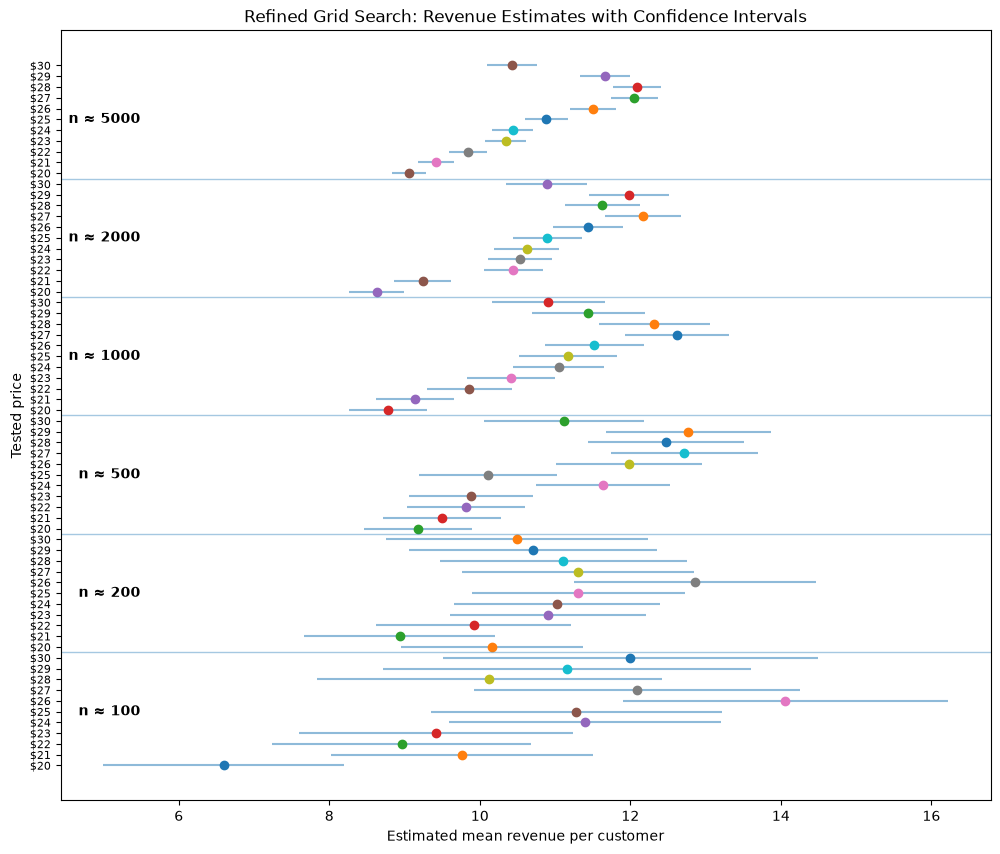

In [237]:
plot_df = (
    refined_grid_df
    .sort_values(["mean_customers", "price"])
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(12, 10))

for i, row in plot_df.iterrows():
    ax.hlines(
        y=i,
        xmin=row["ci_low"],
        xmax=row["ci_high"],
        alpha=0.5,
        linewidth=1.5
    )

    ax.plot(
        row["mean_revenue"],
        i,
        "o"
    )

# label each row by price
ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels(
    [f"${p:.0f}" for p in plot_df["price"]],
    fontsize=8
)

# add sample-size group labels and separator lines
for sample_size, group in plot_df.groupby("mean_customers"):
    start = group.index.min()
    end = group.index.max()
    midpoint = (start + end) / 2

    ax.text(
        plot_df["ci_low"].min() + 0.5,
        midpoint,
        f"n ≈ {sample_size}",
        ha="right",
        va="center",
        fontweight="bold"
    )

    if end < len(plot_df) - 1:
        ax.axhline(
            end + 0.5,
            linewidth=1,
            alpha=0.4
        )

ax.set_xlabel("Estimated mean revenue per customer")
ax.set_ylabel("Tested price")
ax.set_title("Refined Grid Search: Revenue Estimates with Confidence Intervals")

plt.show()

In [238]:
# set up for local search 

def estimate_gradient(price, *, step=1.0, mean_customers=300, critical_value=1.645, rng=None):
    if step <= 0:
        raise ValueError("step must be positive")
    rng = np.random.default_rng(rng)
    price = float(np.clip(price, 0, 75))
    price_low = max(0, price - step)
    price_high = min(75, price + step)
    low = price_low * sales(price_low, mean_customers=mean_customers, rng=rng)
    high = price_high * sales(price_high, mean_customers=mean_customers, rng=rng)
    if min(len(low), len(high)) < 2:
        raise ValueError("Need at least two customers per arm; increase mean_customers.")

    difference = high.mean() - low.mean()
    se = np.sqrt(low.var(ddof=1) / len(low) + high.var(ddof=1) / len(high))
    gap = price_high - price_low
    return {
        "price": price,
        "gradient": difference / gap,
        "gradient_se": se / gap,
        "ci_low": (difference - critical_value * se) / gap,
        "ci_high": (difference + critical_value * se) / gap,
        "customers": len(low) + len(high),
        "experimental_revenue": low.sum() + high.sum()
    }


def gradient_ascent(
    start_price,
    iterations=20,
    step=1.0,
    learning_rate=2.0,
    mean_customers=5000,
    seed=100
):
    rng = np.random.default_rng(seed)

    price = float(start_price)
    records = []

    for iteration in range(iterations):

        estimate = estimate_gradient(
            price=price,
            step=step,
            mean_customers=mean_customers,
            rng=rng
        )

        optimal_revenue = estimate["customers"] * 11.925

        opportunity_cost = (
            optimal_revenue - estimate["experimental_revenue"]
        )

        percent_optimal = (
            estimate["experimental_revenue"]
            / optimal_revenue
        ) * 100

        gradient = estimate["gradient"]

        # decrease learning rate over time
        current_learning_rate = learning_rate / np.sqrt(iteration + 1)

        # proposed change in price
        price_change = current_learning_rate * gradient

        # prevent a single noisy gradient from causing a huge jump
        price_change = np.clip(price_change, -2, 2)

        new_price = price + price_change

        # keep price in allowed range
        new_price = np.clip(new_price, 0, 70)

        records.append({
            "iteration": iteration,
            "price": price,
            "gradient": gradient,
            "gradient_se": estimate["gradient_se"],
            "ci_low": estimate["ci_low"],
            "ci_high": estimate["ci_high"],
            "customers": estimate["customers"],
            "experimental_revenue": estimate["experimental_revenue"],
            "optimal_revenue": optimal_revenue,
            "opportunity_cost": opportunity_cost,
            "percent_optimal": percent_optimal,
            "learning_rate": current_learning_rate,
            "new_price": new_price
        })

        price = new_price

    return pd.DataFrame(records)

In [239]:
local_results = gradient_ascent(
    start_price=27,
    iterations=20,
    step=1.0,
    learning_rate=2.0,
    mean_customers=10000,
    seed=100
)

local_results

,iteration,price,gradient,gradient_se,ci_low,ci_high,customers,experimental_revenue,optimal_revenue,opportunity_cost,percent_optimal,learning_rate,new_price
0,0,27.000000,0.212396,0.094535,0.056886,0.367906,20097,236974.000000,239656.725,2682.725000,98.880597,2.000000,27.424791
1,1,27.424791,-0.031757,0.096085,-0.189816,0.126302,19992,237213.117783,238404.600,1191.482217,99.500227,1.414214,27.379880
2,2,27.379880,-0.062207,0.095634,-0.219525,0.095111,20019,232707.537749,238726.575,6019.037251,97.478690,1.154701,27.308049
3,3,27.308049,-0.102676,0.095547,-0.259851,0.054500,20035,235918.475156,238917.375,2998.899844,98.744796,1.000000,27.205374
4,4,27.205374,0.226424,0.094916,0.070287,0.382561,20209,239577.137956,240992.325,1415.187044,99.412767,0.894427,27.407894
5,5,27.407894,0.133690,0.096437,-0.024949,0.292328,19804,233154.809086,236162.700,3007.890914,98.726348,0.816497,27.517051
6,6,27.517051,0.042085,0.096188,-0.116144,0.200314,20093,239018.794761,239609.025,590.230239,99.753669,0.755929,27.548865
7,7,27.548865,0.038057,0.096953,-0.121431,0.197546,19768,233054.335337,235733.400,2679.064663,98.863519,0.707107,27.575775
8,8,27.575775,0.161677,0.096932,0.002223,0.321131,19825,233106.786054,236413.125,3306.338946,98.601457,0.666667,27.683560
9,9,27.683560,-0.178019,0.096748,-0.337169,-0.018868,19894,230071.321331,237235.950,7164.628669,96.979957,0.632456,27.570971


In [240]:
total_customers = local_results["customers"].sum()

total_revenue = local_results["experimental_revenue"].sum()

total_optimal_revenue = total_customers * 11.925

total_opportunity_cost = (
    total_optimal_revenue - total_revenue
)

percent_optimal_captured = (
    total_revenue / total_optimal_revenue
) * 100

In [241]:
# ----------------------------------------
# SUMMARIZE ALL EXPERIMENTATION STAGES
# ----------------------------------------

optimal_revenue_per_customer = 11.925


# 1. COARSE GRID SEARCH
coarse_customers = grid_df["customers"].sum()

coarse_revenue = (
    grid_df["mean_revenue"] * grid_df["customers"]
).sum()


# 2. REFINED GRID SEARCH
refined_customers = refined_grid_df["customers"].sum()

refined_revenue = (
    refined_grid_df["mean_revenue"] * refined_grid_df["customers"]
).sum()


# 3. LOCAL SEARCH
local_customers = local_results["customers"].sum()

local_revenue = local_results["experimental_revenue"].sum()


# 4. CREATE STAGE-BY-STAGE SUMMARY
experiment_summary = pd.DataFrame({
    "stage": [
        "Coarse Grid",
        "Refined Grid",
        "Local Search"
    ],
    "customers": [
        coarse_customers,
        refined_customers,
        local_customers
    ],
    "revenue": [
        coarse_revenue,
        refined_revenue,
        local_revenue
    ]
})


# 5. TOTALS ACROSS THE ENTIRE SEARCH
total_customers = experiment_summary["customers"].sum()

total_revenue = experiment_summary["revenue"].sum()

total_optimal_revenue = (
    total_customers * optimal_revenue_per_customer
)

total_opportunity_cost = (
    total_optimal_revenue - total_revenue
)

percent_optimal_captured = (
    total_revenue / total_optimal_revenue
) * 100


# 6. ADD STAGE-LEVEL PERFORMANCE METRICS
experiment_summary["optimal_revenue"] = (
    experiment_summary["customers"]
    * optimal_revenue_per_customer
)

experiment_summary["opportunity_cost"] = (
    experiment_summary["optimal_revenue"]
    - experiment_summary["revenue"]
)

experiment_summary["percent_optimal_captured"] = (
    experiment_summary["revenue"]
    / experiment_summary["optimal_revenue"]
) * 100


# 7. CREATE OVERALL SUMMARY
overall_summary = pd.DataFrame({
    "total_customers": [total_customers],
    "total_revenue": [total_revenue],
    "total_optimal_revenue": [total_optimal_revenue],
    "total_opportunity_cost": [total_opportunity_cost],
    "percent_optimal_captured": [percent_optimal_captured]
})


# 8. DISPLAY RESULTS
display(experiment_summary)
display(overall_summary)

,stage,customers,revenue,optimal_revenue,opportunity_cost,percent_optimal_captured
0,Coarse Grid,131545,7.908000e+05,1568674.125,777874.125000,50.412000
1,Refined Grid,96969,1.042448e+06,1156355.325,113907.325000,90.149453
2,Local Search,399434,4.698668e+06,4763250.450,64582.412934,98.644152


,total_customers,total_revenue,total_optimal_revenue,total_opportunity_cost,percent_optimal_captured
0,627948,6.531916e+06,7488279.9,956363.862934,87.228524
